# CNN Feature Visualization, Parameter Audit & Critical Analysis
**Student Name:** Muhammad Taha  |  **Roll No:** FA23-BAI-055  

## Part I: Filter Pipeline
### Setup and image loading
Set `IMAGE_PATH` to your own image (e.g., the building in Figure 2). If the file is missing, a synthetic building-like image is generated so the notebook still runs.

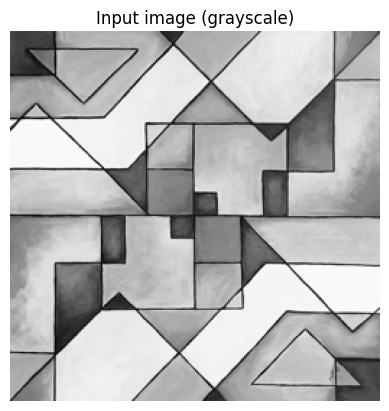

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d
from PIL import Image

IMAGE_PATH = "/content/legacy_products%2FART_464_66818__77221.png"   # <-- change to your image path

def synthetic_building(h=256, w=256):
    img = np.full((h, w), 200.0)
    for r in range(16, h - 16, 48):
        for c in range(16, w - 16, 40):
            img[r:r+30, c:c+24] = 40.0      # dark windows
            img[r+14:r+16, c:c+24] = 120.0  # window bar
    img[:, ::64] = 90.0                      # vertical columns
    return img

if os.path.exists(IMAGE_PATH):
    img = np.array(Image.open(IMAGE_PATH).convert("L").resize((256, 256)), dtype=np.float64)
else:
    print("Image not found, using synthetic image.")
    img = synthetic_building()

img = img / 255.0 if img.max() > 1 else img
plt.imshow(img, cmap="gray"); plt.title("Input image (grayscale)"); plt.axis("off"); plt.show()

### Five 3×3 kernels

In [13]:
kernels = {
    "Horizontal Edge (Sobel-X)": np.array([[-1, -2, -1],
                                           [ 0,  0,  0],
                                           [ 1,  2,  1]], dtype=np.float64),
    "Vertical Edge (Sobel-Y)":   np.array([[-1, 0, 1],
                                           [-2, 0, 2],
                                           [-1, 0, 1]], dtype=np.float64),
    "Sharpen":                   np.array([[ 0, -1,  0],
                                           [-1,  5, -1],
                                           [ 0, -1,  0]], dtype=np.float64),
    "Box Blur":                  np.ones((3, 3), dtype=np.float64) / 9.0,
    "Emboss":                    np.array([[-2, -1, 0],
                                           [-1,  1, 1],
                                           [ 0,  1, 2]], dtype=np.float64),
}
# Note: "Sobel-X" here is named for the horizontal-edge response (it responds to
# intensity change along the vertical direction). Be ready to explain this in the viva.

### Stages A–D

In [14]:
def conv2d(x, k):
    # CNN-style cross-correlation, 'same' output size, zero padding
    return correlate2d(x, k, mode="same", boundary="fill", fillvalue=0)

def relu(x):
    return np.maximum(0, x)

def pool2x2(x, mode="max"):
    h, w = (x.shape[0] // 2) * 2, (x.shape[1] // 2) * 2
    x = x[:h, :w].reshape(h // 2, 2, w // 2, 2)
    return x.max(axis=(1, 3)) if mode == "max" else x.mean(axis=(1, 3))

results = {}
for name, k in kernels.items():
    A = conv2d(img, k)          # Stage A: raw convolution
    B = relu(A)                 # Stage B: post-ReLU
    Cm = pool2x2(B, "max")      # Stage C: max pooling
    D = pool2x2(B, "avg")       # Stage D: average pooling
    results[name] = (A, B, Cm, D)
    print(f"{name:28s} A:{A.shape} B:{B.shape} C:{Cm.shape} D:{D.shape}  "
          f"A min/max=({A.min():.2f},{A.max():.2f})")

Horizontal Edge (Sobel-X)    A:(256, 256) B:(256, 256) C:(128, 128) D:(128, 128)  A min/max=(-3.76,3.73)
Vertical Edge (Sobel-Y)      A:(256, 256) B:(256, 256) C:(128, 128) D:(128, 128)  A min/max=(-3.92,3.94)
Sharpen                      A:(256, 256) B:(256, 256) C:(128, 128) D:(128, 128)  A min/max=(-1.90,3.09)
Box Blur                     A:(256, 256) B:(256, 256) C:(128, 128) D:(128, 128)  A min/max=(0.11,0.99)
Emboss                       A:(256, 256) B:(256, 256) C:(128, 128) D:(128, 128)  A min/max=(-3.02,4.51)


### 5 × 4 visualization grid
Intensity scaling is consistent within each row: Stage A is symmetric around 0 (diverging colormap, so negatives are visible); Stages B, C, D share the same 0 to max range.

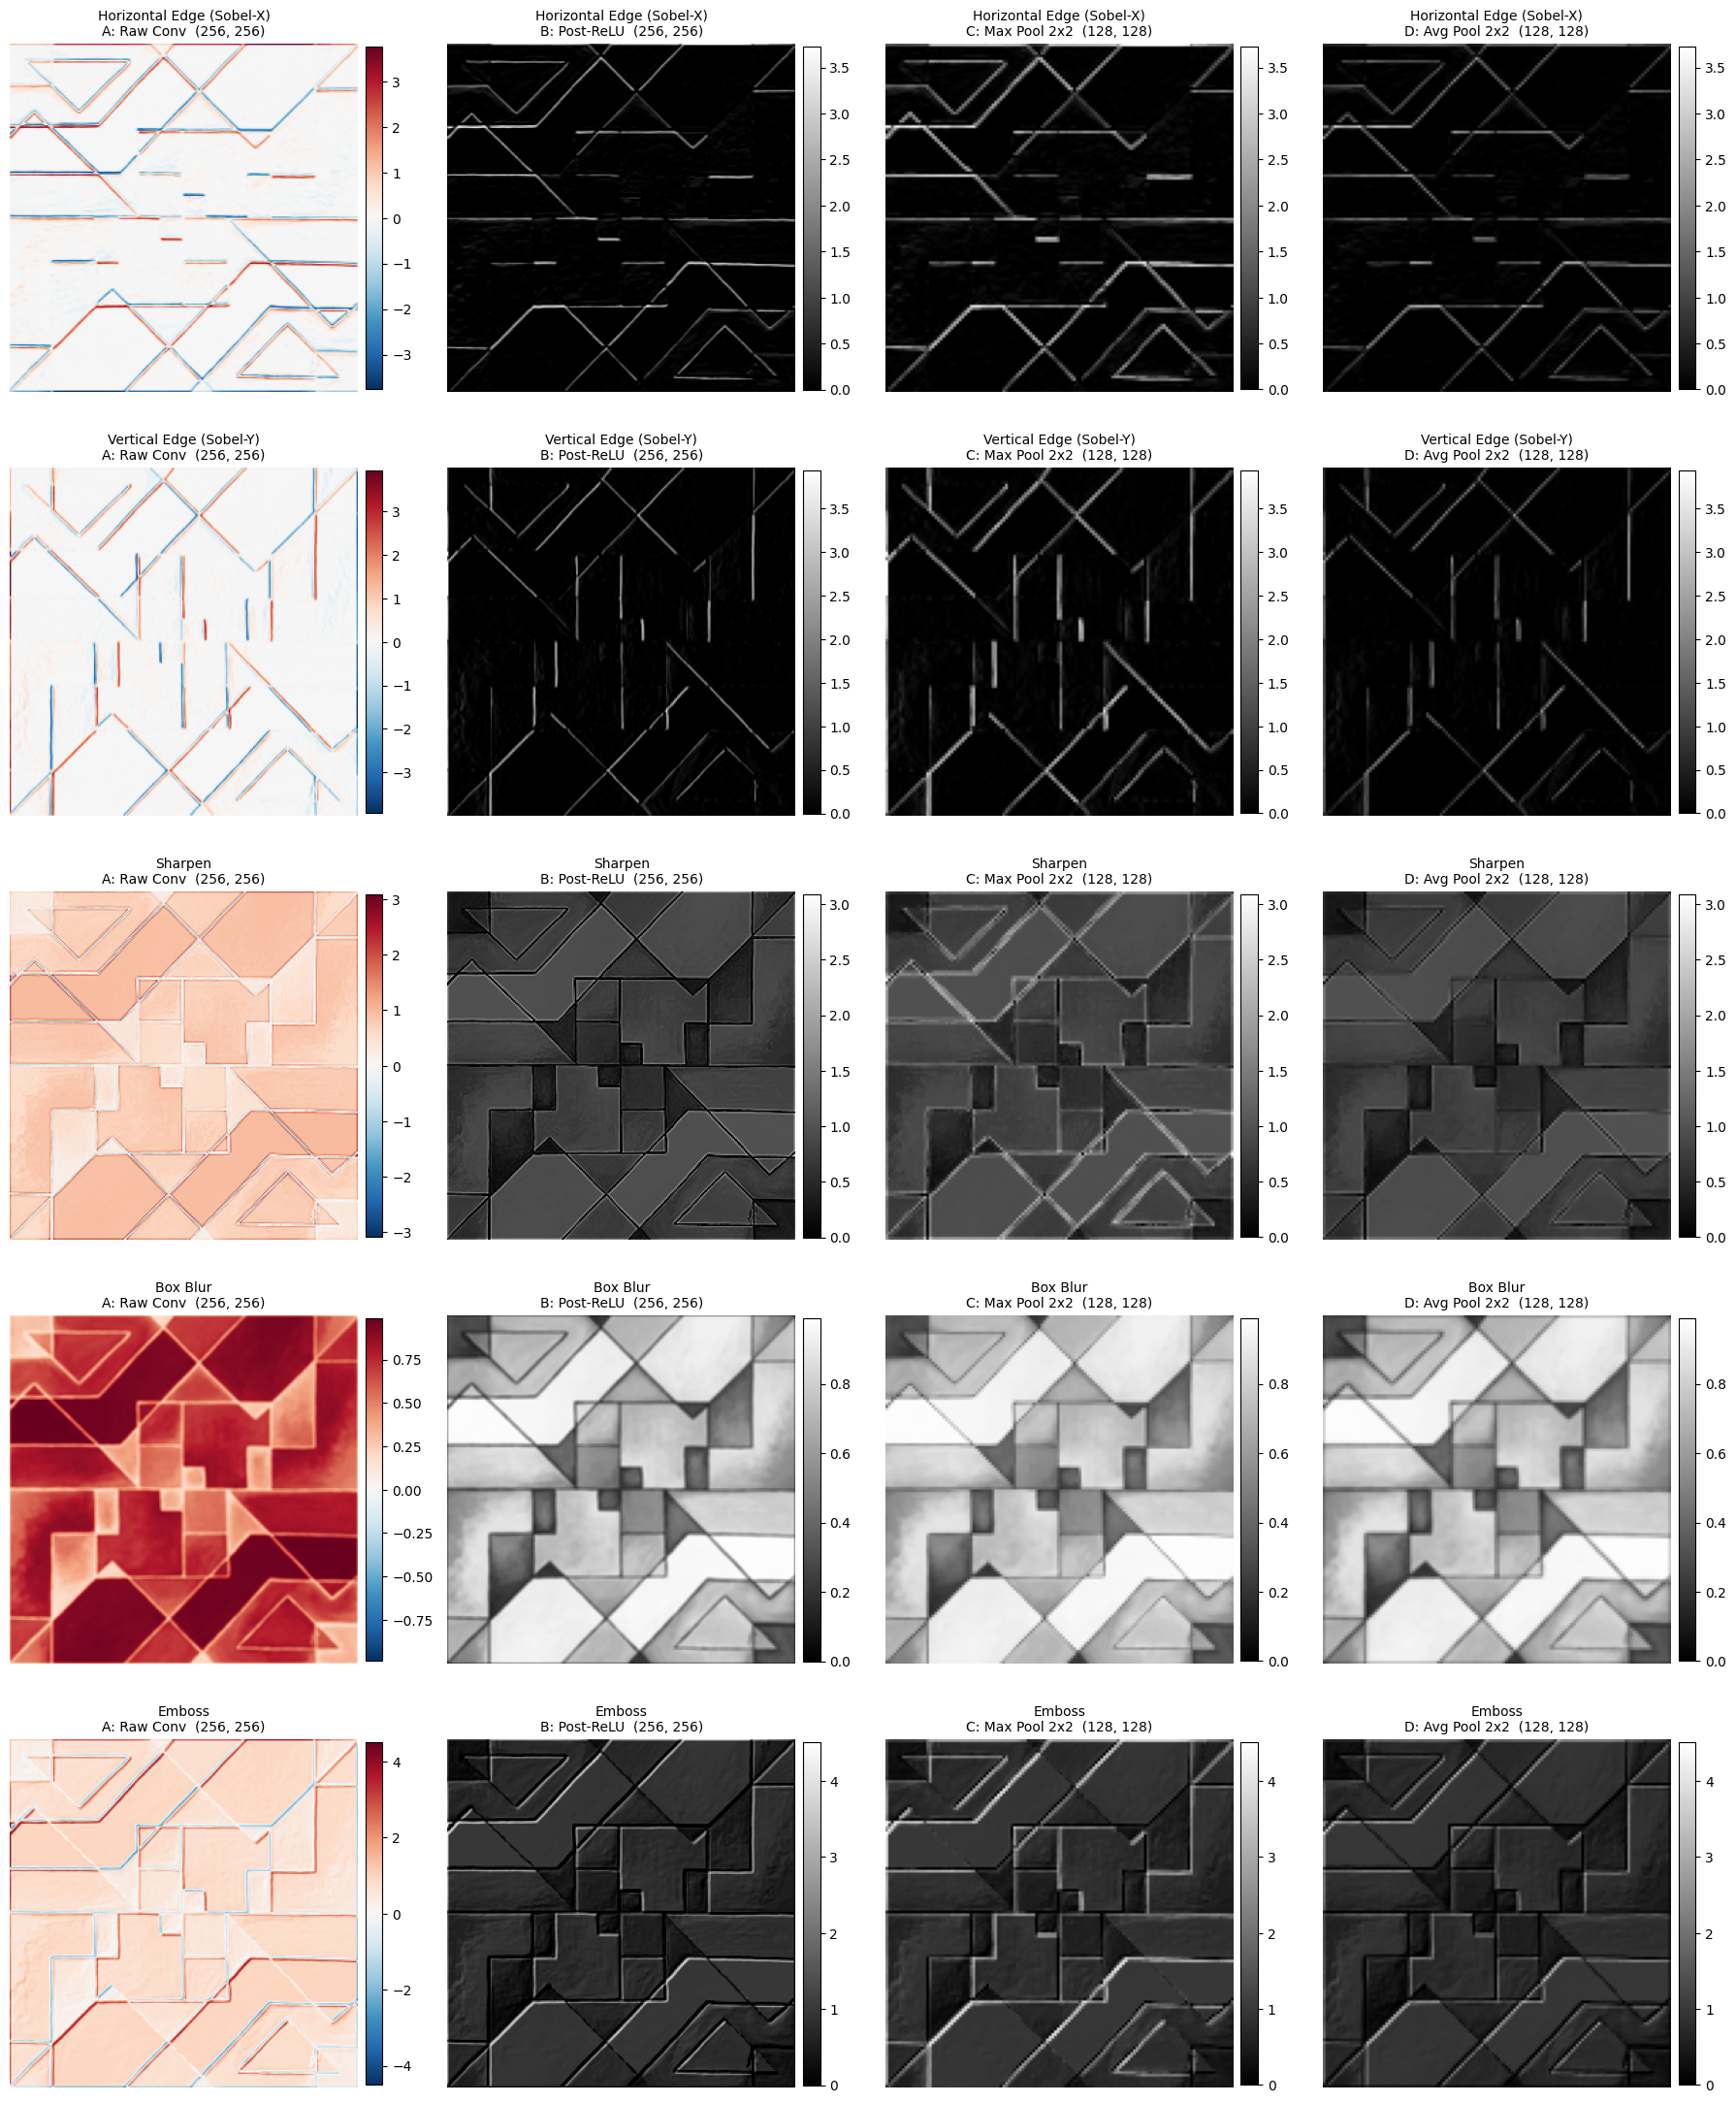

In [15]:
stage_titles = ["A: Raw Conv", "B: Post-ReLU", "C: Max Pool 2x2", "D: Avg Pool 2x2"]
fig, axes = plt.subplots(5, 4, figsize=(18, 22))
for i, (name, maps) in enumerate(results.items()):
    A, B, Cm, D = maps
    amax = np.abs(A).max() + 1e-9
    bmax = B.max() + 1e-9
    for j, m in enumerate(maps):
        ax = axes[i, j]
        if j == 0:
            im = ax.imshow(m, cmap="RdBu_r", vmin=-amax, vmax=amax)
        else:
            im = ax.imshow(m, cmap="gray", vmin=0, vmax=bmax)
        ax.set_title(f"{name}\n{stage_titles[j]}  {m.shape}", fontsize=10)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.savefig("cnn_grid_5x4.png", dpi=150, bbox_inches="tight")
plt.show()

## Part II: Architecture Comparison & Parameter Audit
Both models: Input 32×32×3 → Conv1 (5 filters) → Pool → Conv2 (10 filters) → Pool → Global Average Pooling → Dense(10). Convolutions use `padding='same'`; pooling and GAP have 0 trainable parameters.

**Hand calculation, using (Kh × Kw × Cin + 1) × Cout:**

**Model A (3×3):**
- Conv1: (3×3×3 + 1) × 5 = 28 × 5 = **140**
- Conv2: (3×3×5 + 1) × 10 = 46 × 10 = **460**
- Dense: (10 + 1) × 10 = **110**
- Total = 140 + 460 + 110 = **710**

**Model B (5×5):**
- Conv1: (5×5×3 + 1) × 5 = 76 × 5 = **380**
- Conv2: (5×5×5 + 1) × 10 = 126 × 10 = **1260**
- Dense: (10 + 1) × 10 = **110**
- Total = 380 + 1260 + 110 = **1750**

In [16]:
import torch
import torch.nn as nn

def make_model(k, pool):
    P = nn.MaxPool2d(2, 2) if pool == "max" else nn.AvgPool2d(2, 2)
    return nn.Sequential(
        nn.Conv2d(3, 5, k, padding=k // 2), nn.ReLU(), P,
        nn.Conv2d(5, 10, k, padding=k // 2), nn.ReLU(), P if pool == "max" else nn.AvgPool2d(2, 2),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        nn.Linear(10, 10),
    )

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

model_A = make_model(3, "max")
model_B = make_model(5, "avg")

manual_A = (3*3*3 + 1)*5 + (3*3*5 + 1)*10 + (10 + 1)*10
manual_B = (5*5*3 + 1)*5 + (5*5*5 + 1)*10 + (10 + 1)*10

print(f"Model A  manual: {manual_A}   code: {count_params(model_A)}")
print(f"Model B  manual: {manual_B}   code: {count_params(model_B)}")

x = torch.randn(1, 3, 32, 32)
print("Output shapes:", model_A(x).shape, model_B(x).shape)

try:
    from torchinfo import summary
    summary(model_A, input_size=(1, 3, 32, 32))
    summary(model_B, input_size=(1, 3, 32, 32))
except ImportError:
    print("Install torchinfo for a Keras-like summary (pip install torchinfo). Layer list below:")
    print(model_A); print(model_B)

Model A  manual: 710   code: 710
Model B  manual: 1750   code: 1750
Output shapes: torch.Size([1, 10]) torch.Size([1, 10])
Install torchinfo for a Keras-like summary (pip install torchinfo). Layer list below:
Sequential(
  (0): Conv2d(3, 5, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(5, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): AdaptiveAvgPool2d(output_size=1)
  (7): Flatten(start_dim=1, end_dim=-1)
  (8): Linear(in_features=10, out_features=10, bias=True)
)
Sequential(
  (0): Conv2d(3, 5, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (1): ReLU()
  (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (3): Conv2d(5, 10, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (4): ReLU()
  (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (6): Adaptive

### Audit table
| Model | Conv Architecture | Kernel | Pooling | Manual Count | Code Output |
|---|---|---|---|---|---|
| A (Standard) | 5, 10 filters | 3×3 | Max (2×2, s2) | 710 | *(run cell above)* |
| B (Large Kernel) | 5, 10 filters | 5×5 | Avg (2×2, s2) | 1750 | *(run cell above)* |

Take a screenshot of the summary output for your report.

## Part III: Critical Thinking (supporting code and notes)
Write your final answers in your own words, referring to *your* grid. The cells below give numerical evidence.

### Q1: ReLU blackout, Leaky ReLU, Sigmoid

Horizontal Edge (Sobel-X): negative pixels in Stage A = 47.5% (these become exactly 0 after ReLU)
Vertical Edge (Sobel-Y): negative pixels in Stage A = 45.7% (these become exactly 0 after ReLU)


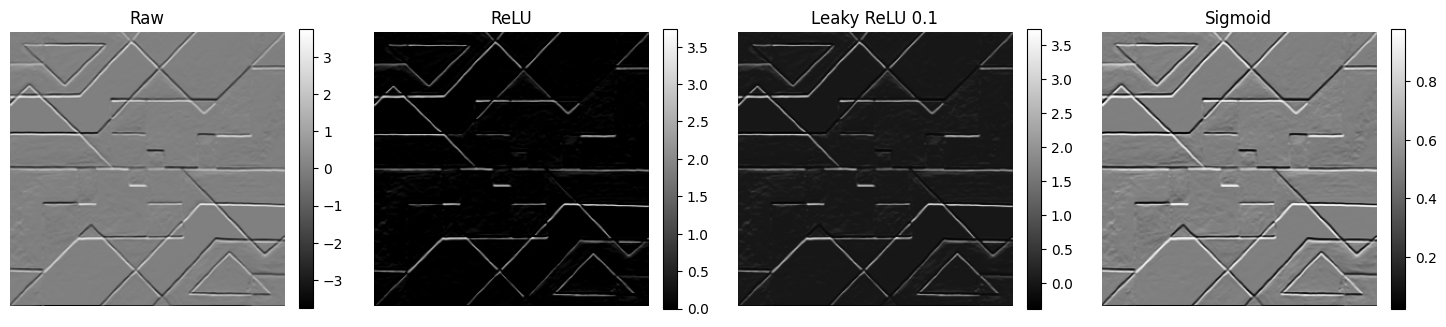

In [17]:
def leaky_relu(x, a=0.1): return np.where(x > 0, x, a * x)
def sigmoid(x): return 1 / (1 + np.exp(-x))

for name in list(kernels)[:2]:
    A = results[name][0]
    print(f"{name}: negative pixels in Stage A = {(A < 0).mean()*100:.1f}% "
          f"(these become exactly 0 after ReLU)")

name = "Horizontal Edge (Sobel-X)"
A = results[name][0]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (t, m) in zip(ax, [("Raw", A), ("ReLU", relu(A)),
                          ("Leaky ReLU 0.1", leaky_relu(A)), ("Sigmoid", sigmoid(A))]):
    im = a.imshow(m, cmap="gray"); a.set_title(t); a.axis("off"); fig.colorbar(im, ax=a, fraction=0.046)
plt.show()
# Notes: negatives appear where intensity goes from bright to dark along the kernel's
# direction (kernel's sign pattern gives negative weighted sum). Leaky ReLU keeps a scaled
# negative response (0.1x). Sigmoid squashes into (0,1): zero input -> 0.5 (flat regions become gray, not black).

### Q2: Max vs. average pooling

In [18]:
# Dark text (low values) on white (255 -> 1.0) background
patch = np.ones((4, 4)); patch[1, 1] = 0.0; patch[2, 2] = 0.0   # two ink pixels
print("Max pool:\n", pool2x2(patch, "max"))
print("Avg pool:\n", pool2x2(patch, "avg"))
# Max pooling picks the brightest value, so it erases dark ink on white (all 1.0).
# Average pooling keeps a trace (0.75). Min pooling, or inverting the image first
# (ink becomes high), would make max pooling preserve strokes.

# Compare sharp peaks on Sharpen row:
A, B, Cm, D = results["Sharpen"]
print("Sharpen  max of Stage C:", Cm.max().round(3), " max of Stage D:", D.max().round(3))

Max pool:
 [[1. 1.]
 [1. 1.]]
Avg pool:
 [[0.75 1.  ]
 [1.   0.75]]
Sharpen  max of Stage C: 3.09  max of Stage D: 1.789


### Q3: Parameter increase and receptive field

In [19]:
inc = (manual_B - manual_A) / manual_A * 100
print(f"Increase A -> B: {manual_B} - {manual_A} = {manual_B - manual_A}  ->  {inc:.2f}%")

# Two stacked 3x3 layers give a 5x5 receptive field (3 + 3 - 1 = 5). Example with C in/out channels:
C = 5
single_5x5 = (5*5*C + 1) * C
two_3x3    = 2 * ((3*3*C + 1) * C)
print(f"C={C}: one 5x5 = {single_5x5}, two 3x3 = {two_3x3}, saved = {single_5x5 - two_3x3} "
      f"({(single_5x5 - two_3x3)/single_5x5*100:.1f}%)")
# Ignoring biases: 25C^2 vs 18C^2 -> 28% fewer weights, plus an extra non-linearity.

Increase A -> B: 1750 - 710 = 1040  ->  146.48%
C=5: one 5x5 = 630, two 3x3 = 460, saved = 170 (27.0%)


### Q4: Order of ReLU and MaxPool

In [20]:
patch = np.array([[-3.0, -1.0],
                  [-2.0,  4.0]])
print("Conv -> ReLU -> MaxPool :", relu(patch).max())
print("Conv -> MaxPool -> ReLU :", relu(np.array(patch.max())))

neg = np.array([[-3.0, -1.0], [-2.0, -5.0]])
print("All-negative patch:", relu(neg).max(), "vs", relu(np.array(neg.max())))

# Random check: identical on many patches
rng = np.random.default_rng(0)
X = rng.normal(size=(10000, 2, 2))
print("Identical on 10000 random patches:", np.allclose(relu(X).max(axis=(1, 2)), relu(X.max(axis=(1, 2)))))
# Proof: ReLU is monotonic non-decreasing, so max(ReLU(x_i)) = ReLU(max(x_i)).
# Efficiency: MaxPool first, then ReLU applies ReLU to 4x fewer values (2x2 pool).
# (This does NOT hold for average pooling, and not for non-monotonic activations.)

Conv -> ReLU -> MaxPool : 4.0
Conv -> MaxPool -> ReLU : 4.0
All-negative patch: 0.0 vs 0.0
Identical on 10000 random patches: True


### Q5: Filter collapse (notes)
Two root causes and fixes (write in your own words):
1. **Poor/symmetric initialization** (e.g., all-zero or identical weights, or tiny weights): filters get identical gradients and stay identical. *Fix:* random He/Kaiming initialization (`nn.init.kaiming_normal_`).
2. **Dead ReLUs from too high a learning rate** (or large negative bias): units output 0 for all inputs, gradients vanish, remaining maps look alike. *Fix:* lower the learning rate / use warmup or Adam with a smaller lr, add BatchNorm, or use Leaky ReLU.

In [21]:
def kaiming_init(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        nn.init.zeros_(m.bias)

model_A.apply(kaiming_init)
w = model_A[0].weight.detach().flatten(1)
cos = torch.nn.functional.cosine_similarity(w[:, None], w[None], dim=-1)
print("Pairwise filter cosine similarity (Layer 1):\n", cos.numpy().round(2))

Pairwise filter cosine similarity (Layer 1):
 [[ 1.    0.05 -0.5  -0.22 -0.15]
 [ 0.05  1.   -0.05 -0.01  0.03]
 [-0.5  -0.05  1.    0.4  -0.38]
 [-0.22 -0.01  0.4   1.   -0.03]
 [-0.15  0.03 -0.38 -0.03  1.  ]]
